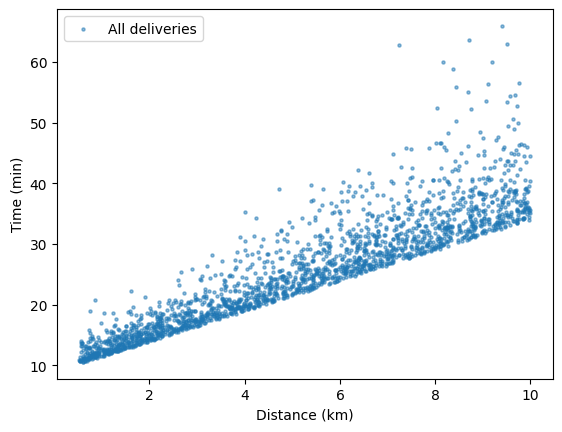

9.556924972002287 [2.84311781]
k and q_hat are: 451 0.4595959595959596


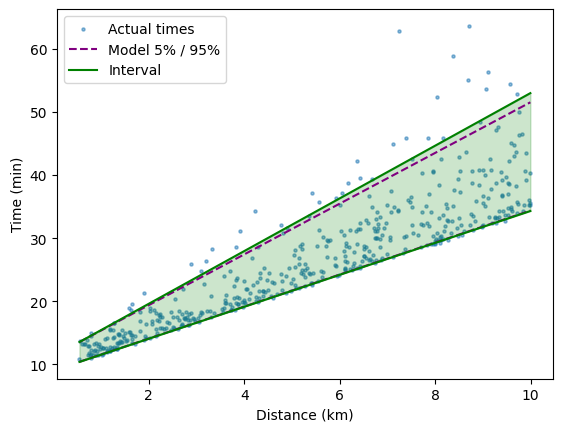

Marginal coverage (all): 0.884
Coverage near (< 3 km):  0.9071428571428571
Coverage far  (> 9 km):  0.9016393442622951
Average width (all): 10.969663713246417
Average width near:  5.041619974105477
Average width far:   17.865741263071335


In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import QuantileRegressor
from sklearn.model_selection import train_test_split


# Step 1: Create the data
# Pizza delivery example with SKEWED noise
#   x      = distance from the store to the customer, 0.5 to 10 km
#   signal = usual delivery time = 10 + 3*x minutes
#            (10 min to prepare the pizza, plus 3 min per km)
#   noise  = random extra time, skewed:
#            at most `scale` minutes early, but sometimes much later
#            (a little faster at best, but traffic jams can add a lot)
#            and it grows with distance (scale = 1 + 0.5*x)
#   y      = actual delivery time = signal + noise
#
# Why skewed: scores 1 and 2 build symmetric intervals and waste width below.

n = 2000          # number of deliveries
lowNum = 0.5      # shortest possible distance (km)
highNum = 10      # longest possible distance (km)

np.random.seed(42)                          # fixed seed -> same random numbers every run
x = np.random.uniform(lowNum, highNum, n)   # n distances, uniformly spread

scale = 1 + 0.5 * x                                    # noise size, grows with distance
noise = scale * (np.random.exponential(1, n) - 1)      # exponential - 1: mean 0, min -1, long tail upward
y = (10 + 3 * x) + noise                               # actual delivery times

plt.scatter(x, y, s=5, alpha=0.5, label="All deliveries")
plt.xlabel("Distance (km)")
plt.ylabel("Time (min)")
plt.legend()
plt.show()


# Step 2: Split the data and train the 99 quantile models

# Split: 1000 training, 500 calibration, 500 test (random, no overlap)
x_train, x_rest, y_train, y_rest = train_test_split(x, y, test_size=0.5, random_state=42)
x_cal, x_test, y_cal, y_test = train_test_split(x_rest, y_rest, test_size=0.5, random_state=42)

X_train = x_train.reshape(-1, 1)   # scikit-learn expects a table: rows = deliveries, 1 column

# Training our quantile regressors for 99 levels 
levels = np.arange(1, 100) / 100 # gives us [0.01, 0.02, ..., 0.99]
quantile_models = []

for tau in levels:
    model = QuantileRegressor(quantile=tau, alpha=0)
    model.fit(X_train, y_train)
    quantile_models.append(model)

print(quantile_models[49].intercept_, quantile_models[49].coef_) # Our median should be around here

# Step 3: Calibrate

alpha = 0.1                      # conformal error rate -> 90% coverage (not the QuantileRegressor alpha!)
X_cal = x_cal.reshape(-1, 1)

# Now we need to walk up our models until one is bigger then real y
# Predict all 99 quantiles for all calibration deliveries, giving a table with 500 rows (deliveries) and 99 columns (levels):
preds_cal = np.column_stack([m.predict(X_cal) for m in quantile_models])

# Count, for each row, how many predictions are below that delivery’s actual time:
counts_cal = (preds_cal < y_cal.reshape(-1, 1)).sum(axis=1)
F_cal = counts_cal / 99
scores = np.abs(F_cal - 0.5)

# q_hat = the ceil((n+1)(1-alpha))-th smallest score
k = math.ceil((len(x_cal) + 1) * (1 - alpha))
q_hat = np.sort(scores)[k - 1]
print("k and q_hat are:", k, q_hat)   # 0.45 = no correction, > 0.45: widen, < 0.45: shrink


# Step 4: Predict intervals on the test set

X_test = x_test.reshape(-1, 1)

preds_test = np.column_stack([m.predict(X_test) for m in quantile_models])
preds_test = np.sort(preds_test, axis=1)

# Allowed count range
c_min = math.ceil(99 * (0.5 - q_hat))
c_max = math.floor(99 * (0.5 + q_hat))

lower_edge = preds_test[:, c_min - 1]
upper_edge = preds_test[:, c_max]

# Sort by distance so the lines are drawn from left to right without zigzagging
order = np.argsort(x_test)

plt.scatter(x_test, y_test, s=5, alpha=0.5, label="Actual times")
plt.plot(x_test[order], preds_test[order, 4], color="purple", linestyle="--", label="Model 5% / 95%")
plt.plot(x_test[order], preds_test[order, 94], color="purple", linestyle="--")
plt.plot(x_test[order], lower_edge[order], color="green", label="Interval")
plt.plot(x_test[order], upper_edge[order], color="green")
plt.fill_between(x_test[order], lower_edge[order], upper_edge[order], color="green", alpha=0.2)
plt.xlabel("Distance (km)")
plt.ylabel("Time (min)")
plt.legend()
plt.show()


# Step 5: Evaluate

# Covered = actual time lies inside its interval
covered = (y_test >= lower_edge) & (y_test <= upper_edge)

near = x_test < 3   # deliveries closer than 3 km
far = x_test > 9    # deliveries further than 9 km

print("Marginal coverage (all):", covered.mean())
print("Coverage near (< 3 km): ", covered[near].mean())
print("Coverage far  (> 9 km): ", covered[far].mean())

# Interval width (efficiency): smaller is better, at the same coverage
width = upper_edge - lower_edge
print("Average width (all):", width.mean())
print("Average width near: ", width[near].mean())
print("Average width far:  ", width[far].mean())